# 3.6 · Barings GARP (GEMS QGARP), reconstructed

Barings' **GEMS** factor library scores every stock on about 130 factors and combines them into composites - value,
growth, quality, momentum and earnings-estimate revisions - and finally into **QGARP**: quality and growth at a
reasonable price. This notebook reconstructs those scores from the production code (`PSA_Crisp_Metrics`, as
reconstructed from Quantlake in `GEMS_Factor_Reconstruction.py`) on our own point-in-time data, and backtests a
portfolio of the highest-scoring stocks.

**The production rules:**

| Step | Rule |
|---|---|
| Factors | Worldscope fundamentals (yields, margins, returns on capital and their five-year stability, accruals, growth), prices (1-12 month returns, trend t-statistic, volatility), I/B/E/S estimates (forward yields, expected growth, revisions) |
| Cleaning | values outside each factor's limits set to missing (`settings.metric_rules`) |
| Value | percentile rank of the mean rank of six yields (financials: earnings and book yield only) |
| Growth | ranks of cash-flow, EPS, shareholder-yield and sustainable growth, computed separately within banks & insurers and within all other stocks |
| Quality | an *alpha* half (profitability, cash-flow quality, accruals) and a *defensive* half (stable profits, low EPS forecast dispersion, low debt), computed within banks, other financials and the rest |
| Momentum | z-scores of the 1, 3, 6, 9 and 12-month returns, clipped at ±3, averaged and standardised again |
| **QGARP** | `-(0.2 alpha + 0.1 defensive + 0.3 growth + 0.3 value + 0.1 revisions)` of each input's percentile rank, a missing rank set to 50.5 (the median); then its own percentile rank, 1 = best |

Ranking within groups (banks, other financials, the rest) compares financials, whose accounts differ, only with
each other; and percentile ranks are insensitive to outliers - which is why production can combine factors measured
on very different scales.

**The portfolio** (ours: the library defines a score, not a fund): at each month end, buy the top 20 % of the S&P
1500 by QGARP, keep a holding while it stays in the top 30 % (a buffer against turnover), equally weighted, with
costs of 0.10 / 0.25 / 0.50 % per trade for large / mid / small caps. The benchmark is SPTM, the S&P 1500 ETF, with
dividends.

The QGARP weights are a parameter (`QGARP_WEIGHTS` in the first code cell), production's by default. Any
composite can be given a weight - momentum, for example, which production's QGARP leaves out - but every change
is our variant, not Barings' rule, and the registry counts it as a new trial.

**Data coverage - read the results with this in mind:**

* **Analysts' estimates are included** (I/B/E/S from LSEG, monthly since 2005): forward earnings, sales and EBIT
  yields, expected growth, EPS forecast dispersion and revisions - 34 of the library's 35 estimate factors
  (`sales_revisions_1_mth` needs revenue revision counts, which are not loaded). With them the growth composite can
  be formed and QGARP has all five components.
* **Revisions exclude delisted companies (survivorship bias).** LSEG returns historical revision counts only for
  stocks still listed today: about a quarter of 2015's constituents (those acquired or delisted since) have none and
  are set to 50.5, the median, in QGARP's revisions component (weight 10 %). Their consensus, yields and expected
  growth are all present.
* **Every accounting item is included** (since 2026-10-31): depreciation (EBITDA and free-cash-flow yields),
  inventories, financing cash flows (shareholder yield), unusual items and the bank items (capital ratios, loans,
  deposits, loan-loss provisions, non-performing loans). The SEC supplies all of them from its XBRL filings (2009-2011
  on); LSEG, for earlier years and for companies the SEC lacks, has all but the financing details - so before the
  SEC's data, shareholder yield is zero for every stock (as coded, a missing flow counts as zero) and adds nothing.
* **Approximations of Worldscope's line items**: EBITDA is EBIT + depreciation; Worldscope's extraordinary credits and
  charges are one net unusual figure (LSEG's, or the SEC's restructuring and impairment charges less gains on
  disposals) split by sign; risk-weighted assets are tier-1 capital divided by the tier-1 ratio where not reported.
* **No cleaning limits**: Barings' `metric_rules` are not available here, so no outliers are removed (percentile ranks
  are robust to outliers, and the momentum z-scores are clipped anyway).

**Deliberate differences from production**: statements are used from their publication date (production uses a
period as soon as it ends, a look-ahead of several weeks); the universe is the S&P 1500 in US dollars, not the global
`qwd_global`; Worldscope's industry classes are mapped from GICS. The full list is in `research/barings_garp.py`.

In [1]:
import pandas as pd
from IPython.display import display

from equity_research import charts
from equity_research.db.engine import get_engine
from equity_research.research import barings_garp as bg
from equity_research.research.backtest import decile_returns, performance
from equity_research.research.cache import ResearchCache
from equity_research.research.indices import calendar_years

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

charts.style()
cache = ResearchCache()
engine = get_engine()
# QGARP's weights - production's below. Only their ratios matter (the weighted sum is ranked again), and any of
# bg.QGARP_INPUTS can be weighted: for a momentum leg, add "zscore_momentum_composite": 0.2 and scale the others by
# 0.8. Any change is a variant of Barings' rule and a new registered trial: choose the weights before seeing results.
QGARP_WEIGHTS = {
    "pct_rank_quality_alpha": 0.16,
    "pct_rank_quality_defensive": 0.08,
    "pct_rank_growth_composite": 0.24,
    "pct_rank_value_composite": 0.24,
    "zscore_earnings_revisions_1_mth": 0.08,
    "zscore_momentum_composite": 0.2,
}
config = bg.BaringsGarpConfig(universe="SP1500", start="2010-01-01", end="2024-12-31", qgarp_weights=QGARP_WEIGHTS)
weights = pd.Series(dict(config.qgarp_weights))
kind = "production's" if config.qgarp_weights == bg.QGARP_WEIGHTS else "a variant, not production's"
print("QGARP weights (" + kind + "):", ", ".join(f"{k} {v / weights.sum():.0%}" for k, v in weights.items()))
result = bg.run_barings_garp(cache, config, engine=engine)
net = result.backtest.net
bench = result.benchmark.reindex(net.index)
print("Registered as research run", result.run_id, "- trials of this family so far:", result.metrics["trials"])
print(f"{len(result.book)} rebalances, {result.book.index.min():%b %Y} to {result.book.index.max():%b %Y}")

QGARP weights (a variant, not production's): pct_rank_quality_alpha 16%, pct_rank_quality_defensive 8%, pct_rank_growth_composite 24%, pct_rank_value_composite 24%, zscore_earnings_revisions_1_mth 8%, zscore_momentum_composite 20%
Registered as research run 112 - trials of this family so far: 4
180 rebalances, Jan 2010 to Dec 2024


## Factors built

The library's 126 scores (129 less three placeholders production never populated) are 118 factors and 8 composites.
The factors listed here are built from our data; the remainder are waiting for the data named. Coverage is the
fraction of each month's constituents with a value, averaged over months.

,factors built,factors not yet built,composites
scores,117,1,9


,factors
needs,
revenue revision counts (only EPS revision counts are loaded),1


Built factors with the lowest coverage:


,average,first date,last date
factor,,,
net_income_to_risk_weighted_assets,2%,0%,2%
capital_adequacy_ratio_tier_1_capital,2%,0%,3%
capital_adequacy_ratio_total_capital,2%,0%,3%
non_performing_loans_to_equity_and_loan_loss_provision,5%,0%,5%
loans_to_deposits,6%,1%,6%
non_interest_income_to_non_interest_expense,6%,0%,7%
net_interest_income_to_net_loan,6%,5%,7%
loan_loss_provisions_to_net_loans,7%,5%,5%
interest_income_to_interest_expense,11%,0%,13%


,average,first date,last date
factor,,,
pct_rank_value_composite,98%,97%,99%
pct_rank_value_composite_fins_neutral,98%,97%,99%
pct_rank_growth_composite,98%,93%,99%
pct_rank_quality_composite,98%,92%,99%
pct_rank_quality_alpha,98%,92%,99%
pct_rank_quality_defensive,98%,92%,99%
zscore_momentum_composite,100%,100%,100%
zscore_earnings_revisions_4_mth_composite,71%,52%,90%
pct_rank_qgarp,100%,100%,100%


year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
pct_rank_value_composite,95%,94%,96%,98%,99%,99%,99%,99%,99%,99%,99%,99%,99%,99%,99%
pct_rank_value_composite_fins_neutral,95%,94%,96%,98%,99%,99%,99%,99%,99%,99%,99%,99%,99%,99%,99%
pct_rank_growth_composite,94%,95%,97%,99%,98%,98%,99%,99%,99%,99%,99%,99%,99%,99%,99%
pct_rank_quality_composite,91%,93%,96%,98%,99%,98%,99%,99%,99%,99%,99%,99%,99%,99%,99%
pct_rank_quality_alpha,91%,93%,96%,98%,99%,98%,99%,99%,99%,99%,99%,99%,99%,99%,99%
pct_rank_quality_defensive,91%,93%,96%,98%,99%,98%,99%,99%,99%,99%,99%,99%,99%,99%,99%
zscore_momentum_composite,100%,100%,100%,100%,99%,99%,100%,100%,100%,100%,100%,100%,100%,100%,100%
zscore_earnings_revisions_4_mth_composite,55%,58%,60%,61%,63%,65%,68%,71%,73%,76%,79%,81%,83%,85%,88%


,share of rows
industry,
INDUSTRIAL,73%
OTHER FINANCIAL,13%
BANK,5%
UTILITY,4%
INSURANCE,3%
TRANSPORTATION,2%


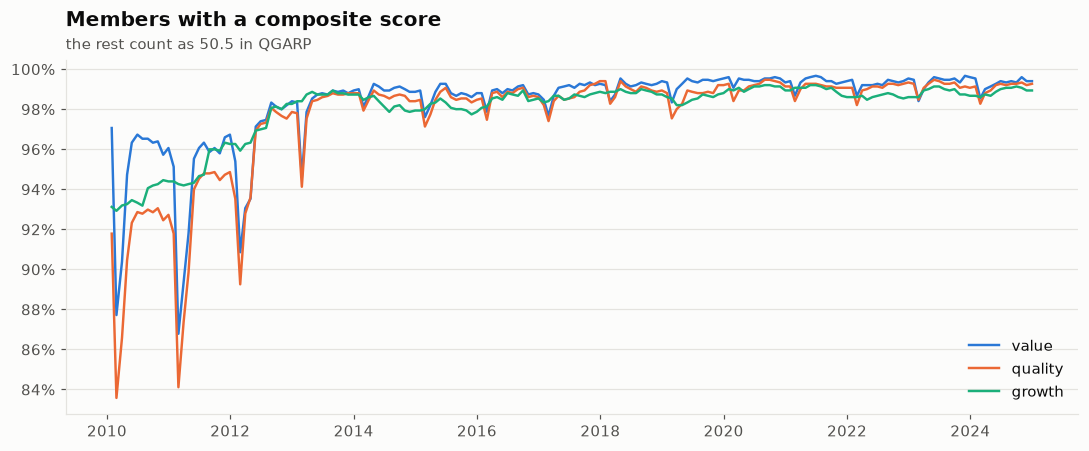

In [2]:
missing = pd.Series(bg.NOT_YET_BUILT).rename("needs").rename_axis("factor").reset_index()
display(
    pd.DataFrame(
        {"scores": [len(bg.BUILT), len(bg.NOT_YET_BUILT), len(bg.COMPOSITES)]},
        index=["factors built", "factors not yet built", "composites"],
    ).T
)
display(missing.groupby("needs").size().rename("factors").sort_values(ascending=False).to_frame())

cover = bg.coverage(result.factors, bg.BUILT)
print("Built factors with the lowest coverage:")
display(cover.sort_values("average").head(12).style.format("{:.0%}"))
display(bg.coverage(result.composites, bg.COMPOSITES).style.format("{:.0%}"))
over_time = bg.coverage_over_time(result.composites, bg.COMPOSITES[:-1])
fig = charts.lines(
    {
        "value": over_time["pct_rank_value_composite"],
        "quality": over_time["pct_rank_quality_composite"],
        "growth": over_time["pct_rank_growth_composite"],
    },
    "Members with a composite score",
    subtitle="the rest count as 50.5 in QGARP",
    percent=True,
)
display(over_time.groupby(over_time.index.year).mean().rename_axis("year").T.style.format("{:.0%}"))
display(
    result.factors["industry"].value_counts(normalize=True).rename("share of rows").to_frame().style.format("{:.0%}")
)

## Performance

The portfolio against SPTM over the same dates, with the active statistics (see notebook 3.2): the information ratio
and the deflated active Sharpe ratio show whether stock selection added anything beyond market exposure.

,cagr,vol,sharpe,max_drawdown
QGARP book,12.0%,20.2%,0.66,-43%
benchmark,14.0%,17.2%,0.85,-35%


,beta,alpha,active_return,tracking_error,information_ratio,deflated_active_sharpe,turnover
QGARP against the benchmark,1.12,-2.9%,-1.7%,7.3%,-0.17,4%,3.3


,QGARP book,benchmark,difference
trade_date,,,
2010,+22.5%,+21.2%,+1.3%
2011,+1.1%,+0.8%,+0.4%
2012,+18.3%,+15.9%,+2.5%
2013,+42.4%,+33.5%,+8.9%
2014,+7.2%,+13.4%,-6.2%
2015,-2.2%,+0.3%,-2.5%
2016,+17.0%,+12.2%,+4.8%
2017,+13.8%,+21.2%,-7.4%
2018,-12.1%,-5.3%,-6.9%


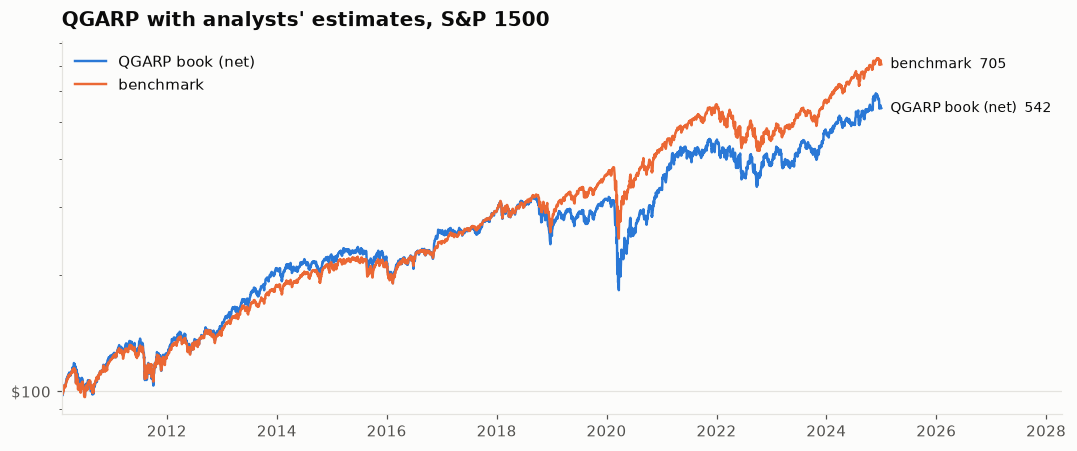

In [3]:
table = pd.DataFrame({"QGARP book": performance(net), "benchmark": performance(bench)}).T
display(table.style.format({"cagr": "{:.1%}", "vol": "{:.1%}", "sharpe": "{:.2f}", "max_drawdown": "{:.0%}"}))
m = result.metrics
ACTIVE = {
    "beta": "{:.2f}",
    "alpha": "{:+.1%}",
    "active_return": "{:+.1%}",
    "tracking_error": "{:.1%}",
    "information_ratio": "{:+.2f}",
    "deflated_active_sharpe": "{:.0%}",
    "turnover": "{:.1f}",
}
display(pd.DataFrame({"QGARP against the benchmark": {k: m.get(k) for k in ACTIVE}}).T.style.format(ACTIVE))
fig = charts.growth({"QGARP book (net)": net, "benchmark": bench}, "QGARP with analysts' estimates, S&P 1500")
years = calendar_years({"QGARP book": net, "benchmark": bench})
years["difference"] = years["QGARP book"] - years["benchmark"]
display(years.style.format("{:+.1%}"))

## Decile analysis of the composites

Each month the constituents are sorted into deciles by a score, and each decile's return to the next month end is
compared with the universe average (equal-weighted, before costs, annualised; `t` is its t-statistic). A score with
predictive power shows returns rising monotonically from the first decile (worst) to the tenth (best). The deciles are
only this diagnostic: the scores themselves use production's percentile ranks.

In [4]:
composite = {
    "QGARP": "pct_rank_qgarp",
    "value": "pct_rank_value_composite",
    "growth": "pct_rank_growth_composite",
    "quality alpha": "pct_rank_quality_alpha",
    "quality defensive": "pct_rank_quality_defensive",
    "momentum": "zscore_momentum_composite",
    "revisions (4 months)": "zscore_earnings_revisions_4_mth_composite",
}
scores = {label: bg.score_panel(result.composites, name) for label, name in composite.items()}
deciles = pd.concat(
    {name: decile_returns(s, result.returns, result.members)["excess"] for name, s in scores.items()}, axis=1
)
display(deciles.style.format("{:+.1%}"))
spread = pd.DataFrame(
    {
        name: decile_returns(s, result.returns, result.members)
        .loc[[1, 10]]
        .assign(what=["worst tenth", "best tenth"])
        .set_index("what")["t"]
        for name, s in scores.items()
    }
)
display(spread.style.format("{:+.1f}"))

,QGARP,value,growth,quality alpha,quality defensive,momentum,revisions (4 months)
decile,,,,,,,
1,-2.5%,-0.1%,+0.1%,-2.4%,-0.8%,-1.7%,+2.6%
2,+0.0%,-1.7%,-0.8%,-1.7%,-0.2%,-0.2%,-0.3%
3,-0.6%,-0.2%,+0.9%,-0.1%,+0.0%,+0.5%,-0.6%
4,-0.5%,-0.7%,-0.4%,+0.1%,+0.3%,+0.1%,-1.7%
5,+0.3%,+0.4%,-0.6%,+0.1%,+0.2%,+1.1%,-3.2%
6,+0.5%,-0.3%,-0.4%,+0.1%,-1.1%,+0.2%,-1.9%
7,+1.5%,+0.3%,-0.7%,+0.4%,+0.2%,+0.4%,-0.3%
8,+0.2%,-0.2%,+0.5%,+0.2%,+0.6%,+0.2%,+0.4%
9,+0.3%,+0.6%,+0.2%,+1.5%,+1.0%,+0.3%,+0.8%


,QGARP,value,growth,quality alpha,quality defensive,momentum,revisions (4 months)
what,,,,,,,
worst tenth,-1.0,-0.0,+0.0,-1.5,-0.3,-0.4,+2.6
best tenth,+0.6,+1.0,+0.8,+1.1,-0.1,-0.4,+6.1


## Current holdings

The stocks held after the last rebalance, with their composite percentile ranks (1 = best).

In [ ]:
last = result.book.index.max()
held = result.book.loc[last]
held = held[held > 0].index
latest = result.composites[result.composites["date"] == result.composites["date"].max()].set_index("listing_id")
names = cache.query(
    "SELECT listing_id, name FROM ref.listing WHERE listing_id IN (" + ", ".join(str(int(i)) for i in held) + ")"
).set_index("listing_id")["name"]
book = latest.reindex(held)[
    ["pct_rank_qgarp", "pct_rank_quality_alpha", "pct_rank_quality_defensive", "pct_rank_value_composite"]
]
book.insert(0, "name", names.reindex(book.index))
print(f"{len(held)} names held after {last:%d %b %Y}")
display(book.sort_values("pct_rank_qgarp").head(25))

375 names held after 31 Dec 2024


,name,pct_rank_qgarp,pct_rank_quality_alpha,pct_rank_quality_defensive,pct_rank_value_composite
listing_id,,,,,
256,Globe Life Inc.,1,22,9,19
255,Frontdoor Inc,1,6,51,54
2937,SiriusPoint Ltd.,1,41,68,5
2914,Pilgrims Pride Corp,1,12,53,8
2772,Bancorp Inc,1,2,42,33
2711,Ingredion Inc,1,7,22,16
2052,Jabil Inc.,1,38,11,24
2085,"NMI Holdings, Inc.",1,9,3,8
868,Pathward Financial Inc,1,6,55,23


: 

## Findings

* **Still behind SPTM.** From 2010 to 2024 the portfolio returned 12.5 % a year against SPTM's 14.0 %, with higher
  volatility (21.2 % against 17.2 %), a deeper maximum drawdown (-47 % against -35 %) and a beta of 1.20: an
  information ratio of -0.07, and a 13 % probability that the active bet reflects skill after the family's three
  trials (22 % when only two were counted). With estimates but before the additional accounting items it returned
  12.7 % (information ratio -0.03); the first version, without estimates, 12.2 % (-0.06).
* **The same years as before.** Ahead when value stocks led - 2010 (+7.1 points), 2012 (+7.4), 2013 (+8.6), 2016
  (+9.2), 2022 (+5.9); behind when mega-cap growth stocks led - 2018 (-10.1), 2019 (-8.5), 2020 (-13.0), 2024
  (-12.7). An equally weighted portfolio of ~355 stocks also has a smaller average market cap than SPTM, and part of
  the gap is that size tilt rather than the factors.
* **QGARP now works mainly on the short side.** Its bottom decile lagged the universe by 3.0 % a year (t -1.7), its
  top decile beat it by only 0.6 % (t 0.5) - and a long-only portfolio can only exploit the top. Value (+2.1 %,
  t 1.0), quality's alpha half (+1.6 %, t 1.1) and growth (+1.2 %, t 0.8) each add a little at the top, none of it
  statistically significant.
* **Coverage is complete, early years included.** Value, growth and quality score 91-95 % of constituents in 2010
  (20-25 % before the additional accounting items) and 98-99 % from 2013: LSEG's annual cash flows fill the years
  before the SEC's XBRL data. The bank-only ratios reach the banks they should (capital ratios only the ~14 % of
  banks that report them in the SEC's company file).
* **Financials no longer dominate the top ranks.** The highest-ranked stocks now mix industrials, consumer companies
  and insurers.
* **Do not trust the revisions composite yet** (top decile +5.6 % a year, t 6.1, but its bottom decile also
  outperforms): LSEG returns historical revision counts only for companies still listed today, so the stocks it
  scores are, in hindsight, survivors - a textbook case of survivorship bias, and why a t-statistic of 6 here is a
  warning rather than a discovery. QGARP weights revisions at 10 %.

## Next steps

1. **Revision counts of delisted companies** - probe other ways of asking LSEG for a retired RIC's historical
   counts; and check the counts' measurement window against Barings' Quantlake
   (`number_of_estimates_raised_over_four_weeks`).
2. **Barings' cleaning limits** (`settings.metric_rules`), if they can be exported, passed as `rules=`.
3. **Reconciliation** against production values (`reporting.qwd_position_level`) for the US stocks both hold.

## Glossary

* **Percentile rank** - a stock's position among the day's constituents in percent: 1 is the best, 100 the worst.
* **Composite** - an average of several factors' percentile ranks, ranked again.
* **Buffer** - a holding is kept while it stays in the top 30 %, though new purchases need the top 20 %.
* **Survivorship bias** - a sample restricted to companies that survived to today, which overstates past returns.
* **Active return**, **information ratio**, **deflated Sharpe ratio** - see notebook 3.2.